# CS 6220: Data Mining Techniques
## Homework 3

## 0. Dependencies & Environment Setup

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display, Image
from collections import Counter
from sklearn.datasets import make_moons
import torch
import torch.nn as nn
import torch.nn.functional as F

# Ensure reproducible figures
np.random.seed(42)
torch.manual_seed(42)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8


In [24]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.


---
# Part 1: K-Nearest Neighbor (k-NN)

### Algorithm Design & Specification
- `knn_predict(X_train, y_train, X_test, y_test, k, distance_func)` implements exact $k$-NN classification.
- General $L_p$ norm:
  $$d_p(\mathbf{u}, \mathbf{v}) = \left(\sum_{i=1}^d |u_i - v_i|^p\right)^{1/p}$$
  where $p=1$ corresponds to Manhattan distance and $p=2$ corresponds to Euclidean distance.
- **Tie-Breaking Rule**: When voting produces a tie among top classes, the algorithm breaks the tie meaningfully by selecting the candidate class with the minimum average distance among its top-$k$ neighbors.


In [25]:

def lp_distance(v1, v2, p=2):
    """Compute the Lp distance between two numerical vectors."""
    v1 = np.asarray(v1, dtype=float)
    v2 = np.asarray(v2, dtype=float)

    if p < 1:
        raise ValueError("p must be at least 1.")

    return float(np.sum(np.abs(v1 - v2) ** p) ** (1.0 / p))


def euclidean_distance(v1, v2):
    """Compute Euclidean distance."""
    return lp_distance(v1, v2, p=2)


def manhattan_distance(v1, v2):
    """Compute Manhattan distance."""
    return lp_distance(v1, v2, p=1)


def knn_get_votes_and_predict(
    X_train, y_train, X_test, k=3,
    distance_func=euclidean_distance
):
    """Return class-vote counts and the predicted class."""
    X_train = np.asarray(X_train, dtype=float)
    y_train = np.asarray(y_train)
    X_test = np.asarray(X_test, dtype=float).ravel()

    if len(X_train) != len(y_train):
        raise ValueError("X_train and y_train must have equal lengths.")
    if len(X_train) == 0:
        raise ValueError("Training data cannot be empty.")
    if not isinstance(k, (int, np.integer)) or isinstance(k, bool):
        raise ValueError("k must be an integer.")
    if not 1 <= k <= len(X_train):
        raise ValueError("k must be between 1 and the training size.")
    if X_train.ndim != 2 or X_train.shape[1] != len(X_test):
        raise ValueError("Test point must match the training feature dimensions.")

    distances = []
    for i in range(len(X_train)):
        d = distance_func(X_train[i], X_test)
        distances.append((d, y_train[i]))

    distances.sort(key=lambda item: item[0])
    k_nearest = distances[:k]

    votes = Counter(label for _, label in k_nearest)
    max_votes = max(votes.values())
    tied_classes = [
        label for label, count in votes.items()
        if count == max_votes
    ]

    # Tie-break using the smallest total distance among tied classes.
    if len(tied_classes) > 1:
        distance_sums = {
            label: sum(d for d, cls in k_nearest if cls == label)
            for label in tied_classes
        }
        prediction = min(
            tied_classes,
            key=lambda label: (distance_sums[label], label)
        )
    else:
        prediction = tied_classes[0]

    return dict(votes), prediction


def knn_predict(
    X_train, y_train, X_test, y_test=None, k=3,
    distance_func=euclidean_distance
):
    """Predict the class of one test record."""
    _, prediction = knn_get_votes_and_predict(
        X_train, y_train, X_test, k, distance_func
    )
    return prediction


### 2D k-NN Visualization Function & Error Computation

In [26]:

def visualize_knn_boundary(
    X_train, y_train, k=3,
    distance_func=euclidean_distance, title=None, ax=None
):
    """
    Visualize the k-NN decision boundary and training records.
    """
    X_train = np.asarray(X_train, dtype=float)
    y_train = np.asarray(y_train)

    if X_train.ndim != 2 or X_train.shape[1] != 2:
        raise ValueError("X_train must contain exactly 2 features.")
    if len(X_train) != len(y_train) or len(X_train) == 0:
        raise ValueError("X_train and y_train must have equal, nonzero lengths.")

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5), dpi=150)

    x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
    y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 100),
        np.linspace(y_min, y_max, 100)
    )
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    preds = np.array([
        knn_predict(
            X_train, y_train, point,
            k=k, distance_func=distance_func
        )
        for point in grid_points
    ]).reshape(xx.shape)

    ax.contourf(
        xx, yy, preds, alpha=0.3,
        cmap=plt.cm.coolwarm, levels=[-0.5, 0.5, 1.5]
    )
    ax.contour(
        xx, yy, preds, colors="black",
        linewidths=1.0, levels=[0.5]
    )

    ax.scatter(
        X_train[y_train == 0, 0], X_train[y_train == 0, 1],
        c="#1f77b4", marker="o", edgecolors="k",
        s=40, label="Class 0"
    )
    ax.scatter(
        X_train[y_train == 1, 0], X_train[y_train == 1, 1],
        c="#d62728", marker="^", edgecolors="k",
        s=45, label="Class 1"
    )

    ax.set_title(title or f"k-NN Decision Boundary (k={k})")
    ax.set_xlabel("Feature 1 ($x_1$)")
    ax.set_ylabel("Feature 2 ($x_2$)")
    ax.legend(loc="upper right")
    ax.grid(True, linestyle="--", alpha=0.5)

    return ax


def compute_knn_errors(
    X, y, k=3, distance_func=euclidean_distance
):
    """
    Compute training error and leave-one-out cross-validation error.
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    n = len(X)

    if X.ndim != 2 or n != len(y) or n == 0:
        raise ValueError("X and y must have equal, nonzero lengths.")
    if not isinstance(k, (int, np.integer)) or isinstance(k, bool):
        raise ValueError("k must be an integer.")
    if not 1 <= k < n:
        raise ValueError("k must be at least 1 and smaller than n.")

    # Training error: each record is included in the training set.
    train_predictions = [
        knn_predict(X, y, X[i], k=k, distance_func=distance_func)
        for i in range(n)
    ]
    train_error_rate = np.mean(np.asarray(train_predictions) != y)

    # LOOCV error: exclude each record from its own training set.
    loocv_errors = 0

    for i in range(n):
        X_train = np.delete(X, i, axis=0)
        y_train = np.delete(y, i, axis=0)

        prediction = knn_predict(
            X_train, y_train, X[i],
            k=k, distance_func=distance_func
        )

        if prediction != y[i]:
            loocv_errors += 1

    test_error_rate = loocv_errors / n

    return train_error_rate, test_error_rate


### Question 3: Experimental Predictions on `make_moons` Dataset
We instantiate the dataset using `sklearn.datasets.make_moons(n_samples=200, noise=0.15)` with `np.random.seed(42)`.  
We evaluate test points:
- $P_1 = (0.40, 0.45)$
- $P_2 = (0.08, 0.78)$
- $P_3 = (0.75, -0.15)$  
across distance measures (Euclidean, Manhattan) and neighbor counts $k \in \{1, 3, 5\}$.


In [27]:
np.random.seed(42)
X_moons, y_moons = make_moons(n_samples=200, noise=0.15)

test_points = [
    (0.40, 0.45),
    (0.08, 0.78),
    (0.75, -0.15)
]

print(
    f"{'Point':<16} | {'Metric':<10} | {'k':<2} | "
    f"{'Class 0 Votes':<13} | {'Class 1 Votes':<13} | "
    f"{'Predicted Class':<15}"
)
print("-" * 85)

for pt in test_points:
    for metric_name, dist_fn in [
        ("Euclidean", euclidean_distance),
        ("Manhattan", manhattan_distance)
    ]:
        for k in [1, 3, 5]:
            votes, pred = knn_get_votes_and_predict(
                X_moons, y_moons, pt, k, dist_fn
            )

            pt_str = f"({pt[0]:.2f}, {pt[1]:.2f})"

            print(
                f"{pt_str:<16} | {metric_name:<10} | {k:<2} | "
                f"{votes.get(0, 0):<13} | {votes.get(1, 0):<13} | "
                f"{pred:<15}"
            )

Point            | Metric     | k  | Class 0 Votes | Class 1 Votes | Predicted Class
-------------------------------------------------------------------------------------
(0.40, 0.45)     | Euclidean  | 1  | 1             | 0             | 0              
(0.40, 0.45)     | Euclidean  | 3  | 1             | 2             | 1              
(0.40, 0.45)     | Euclidean  | 5  | 1             | 4             | 1              
(0.40, 0.45)     | Manhattan  | 1  | 1             | 0             | 0              
(0.40, 0.45)     | Manhattan  | 3  | 1             | 2             | 1              
(0.40, 0.45)     | Manhattan  | 5  | 1             | 4             | 1              
(0.08, 0.78)     | Euclidean  | 1  | 0             | 1             | 1              
(0.08, 0.78)     | Euclidean  | 3  | 2             | 1             | 0              
(0.08, 0.78)     | Euclidean  | 5  | 4             | 1             | 0              
(0.08, 0.78)     | Manhattan  | 1  | 0             | 1          

#### Question 3d: Minimal Example of Euclidean vs. Manhattan Discrepancy
Below, we demonstrate analytically and visually that two points can receive opposite class assignments under Euclidean vs. Manhattan metric despite identical training data and test query.
- Test Point: $(0, 0)$
- Training Point $A = (0.5, 0.5)$, Class 0
- Training Point $B = (0.0, 0.8)$, Class 1

**Distances:**
- **Euclidean ($L_2$):**
  $$d_E(\text{Test}, A) = \sqrt{0.5^2 + 0.5^2} = \sqrt{0.5} \approx 0.7071$$
  $$d_E(\text{Test}, B) = \sqrt{0^2 + 0.8^2} = 0.8000$$
  Since $d_E(\text{Test}, A) < d_E(\text{Test}, B)$, 1-NN predicts **Class 0**.
- **Manhattan ($L_1$):**
  $$d_M(\text{Test}, A) = |0.5| + |0.5| = 1.0000$$
  $$d_M(\text{Test}, B) = |0| + |0.8| = 0.8000$$
  Since $d_M(\text{Test}, B) < d_M(\text{Test}, A)$, 1-NN predicts **Class 1**.


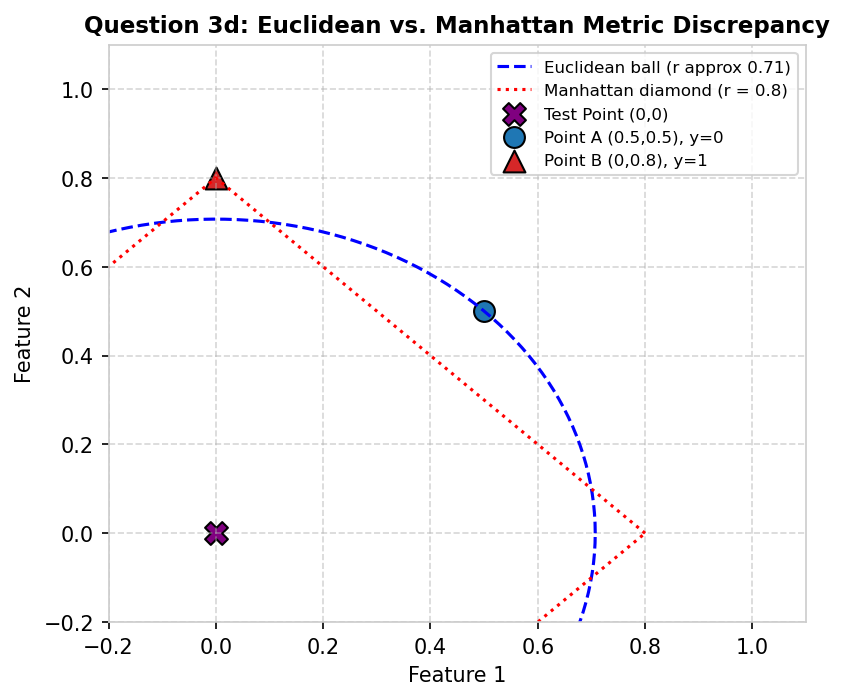

In [28]:
# Visualizing Question 3d Minimal Example
theta = np.linspace(0, 2*np.pi, 200)
fig, ax = plt.subplots(figsize=(6, 5), dpi=150)

ax.plot(0.7071*np.cos(theta), 0.7071*np.sin(theta), 'b--', label='Euclidean ball (r approx 0.71)')
ax.plot([0.8, 0, -0.8, 0, 0.8], [0, 0.8, 0, -0.8, 0], 'r:', label='Manhattan diamond (r = 0.8)')

ax.scatter([0], [0], c='purple', marker='X', s=120, edgecolors='k', label='Test Point (0,0)')
ax.scatter([0.5], [0.5], c='#1f77b4', marker='o', s=100, edgecolors='k', label='Point A (0.5,0.5), y=0')
ax.scatter([0.0], [0.8], c='#d62728', marker='^', s=110, edgecolors='k', label='Point B (0,0.8), y=1')

ax.set_title("Question 3d: Euclidean vs. Manhattan Metric Discrepancy", fontsize=11, fontweight='bold')
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_xlim(-0.2, 1.1)
ax.set_ylim(-0.2, 1.1)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc='upper right', fontsize=8)
plt.show()


In [29]:
X_minimal = np.array([
    [0.5, 0.5],  # Class 0
    [0.0, 0.8]   # Class 1
])
y_minimal = np.array([0, 1])

test_point = np.array([0.0, 0.0])

for name, metric in [
    ("Euclidean", euclidean_distance),
    ("Manhattan", manhattan_distance)
]:
    votes, prediction = knn_get_votes_and_predict(
        X_minimal, y_minimal, test_point,
        k=1, distance_func=metric
    )
    print(f"{name}: votes={votes}, prediction={prediction}")

Euclidean: votes={np.int64(0): 1}, prediction=0
Manhattan: votes={np.int64(1): 1}, prediction=1


### Question 4: 1-NN vs. 10-NN Decision Boundaries & Model Variance

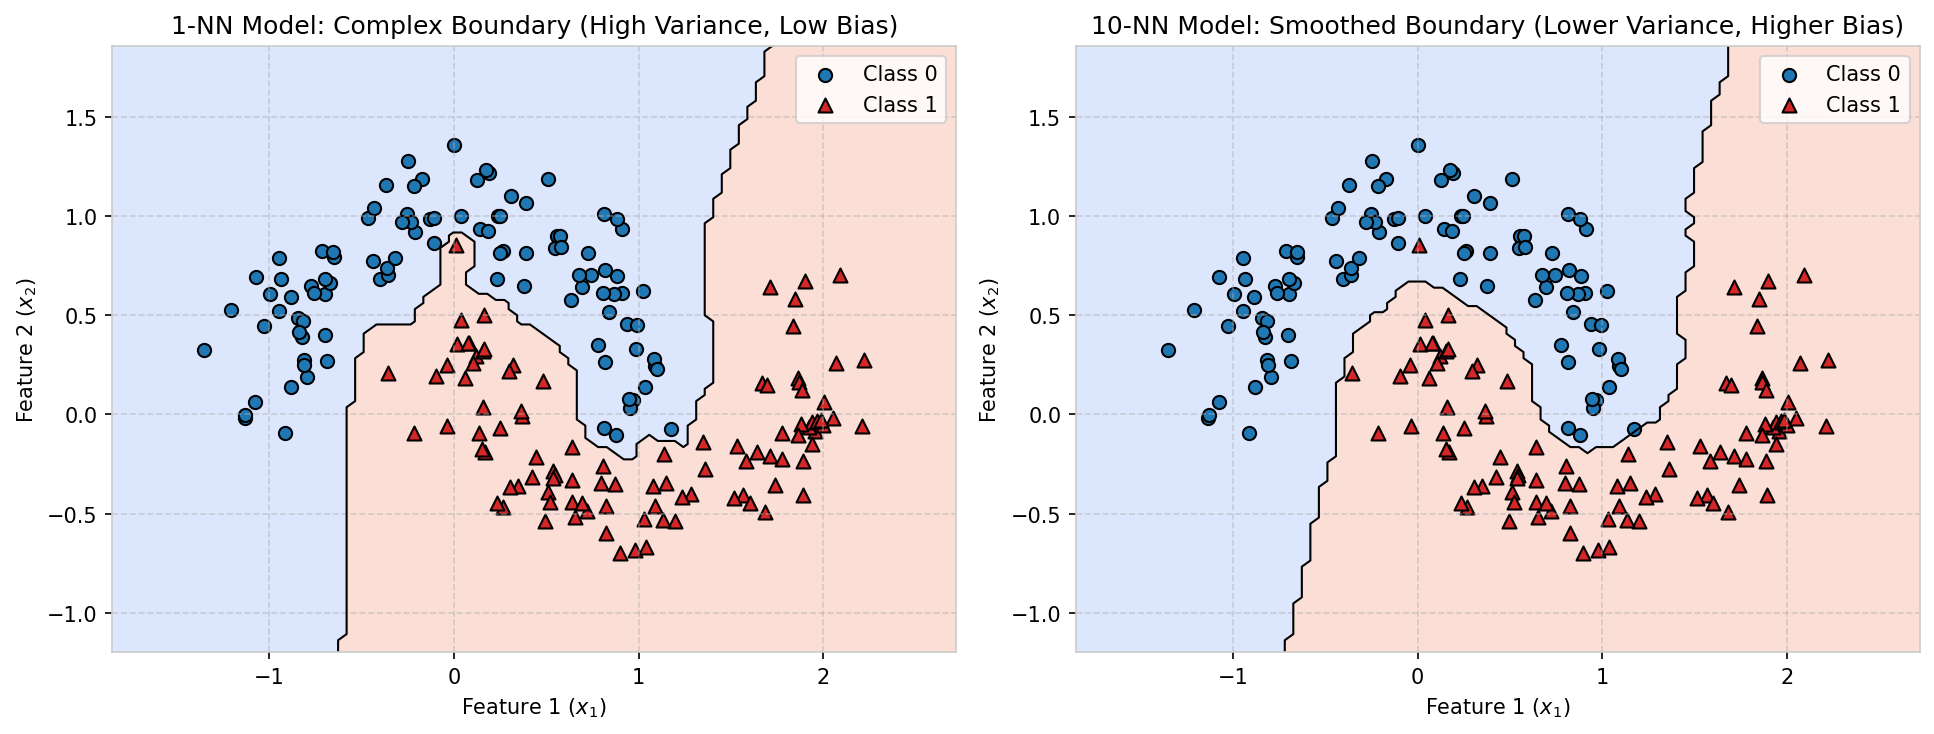

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=150)
visualize_knn_boundary(X_moons, y_moons, k=1, distance_func=euclidean_distance,
                       title="1-NN Model: Complex Boundary (High Variance, Low Bias)", ax=ax1)
visualize_knn_boundary(X_moons, y_moons, k=10, distance_func=euclidean_distance,
                       title="10-NN Model: Smoothed Boundary (Lower Variance, Higher Bias)", ax=ax2)
plt.tight_layout()
plt.show()


### Question 5: k-NN Error Trends from $k=1$ to $k=N$

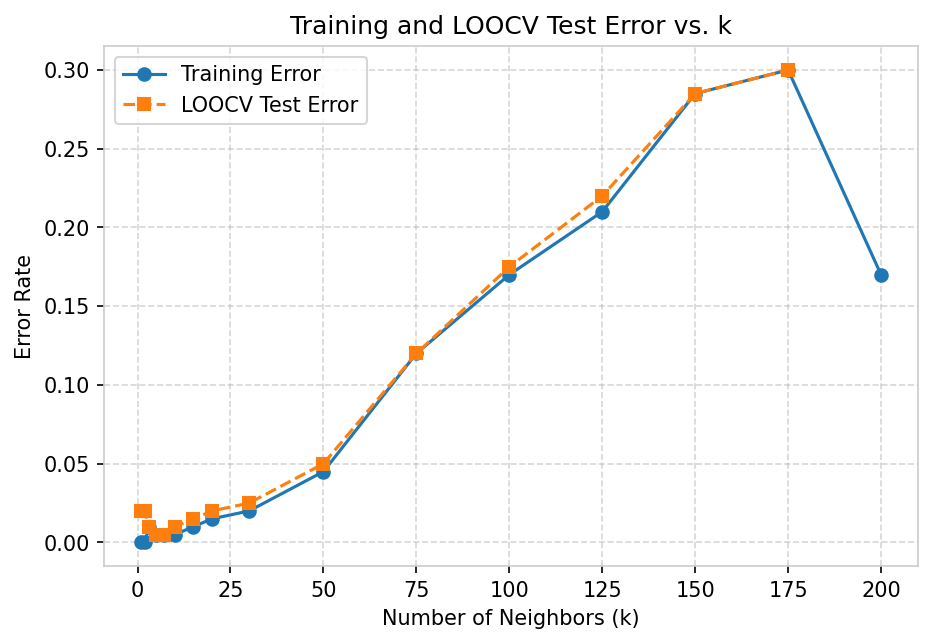

In [31]:
k_vals = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75,
          100, 125, 150, 175, 200]

tr_errs, te_errs = [], []

for k in k_vals:
    if k < len(X_moons):
        tr_e, te_e = compute_knn_errors(
            X_moons, y_moons,
            k=k,
            distance_func=euclidean_distance
        )
        te_errs.append(te_e)
    else:
        # At k=n, every training record votes for every prediction.
        train_predictions = [
            knn_predict(
                X_moons, y_moons, X_moons[i],
                k=k,
                distance_func=euclidean_distance
            )
            for i in range(len(X_moons))
        ]
        tr_e = np.mean(np.asarray(train_predictions) != y_moons)

        # LOOCV is undefined at k=n.
        te_errs.append(np.nan)

    tr_errs.append(tr_e)

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)
ax.plot(k_vals, tr_errs, 'o-', label='Training Error')
ax.plot(k_vals, te_errs, 's--', label='LOOCV Test Error')
ax.set_title("Training and LOOCV Test Error vs. k")
ax.set_xlabel("Number of Neighbors (k)")
ax.set_ylabel("Error Rate")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.show()

---
# Part 2: Neural Networks

### Rosenblatt Perceptron Learning Algorithm
Given training instance $(\mathbf{x}, y)$ with $\mathbf{x} = (x_1, x_2)$ and $y \in \{0, 1\}$:
1. Compute linear activation: $z = w_1 x_1 + w_2 x_2 + b$
2. Heaviside step prediction: $\hat{y} = 1$ if $z \ge 0$ else $0$.
3. Error: $e = y - \hat{y}$
4. Weight and bias updates:
   $$w_1 \leftarrow w_1 + \eta e x_1$$
   $$w_2 \leftarrow w_2 + \eta e x_2$$
   $$b \leftarrow b + \eta e$$


In [32]:
def train_perceptron(training_record, learning_rate, w1, w2, b):
    """
    Implements single-step perceptron training update on record (x1, x2, y).
    """
    x1, x2, y = training_record
    z = w1 * x1 + w2 * x2 + b
    y_hat = 1 if z >= 0.0 else 0
    err = y - y_hat
    
    w1_new = w1 + learning_rate * err * x1
    w2_new = w2 + learning_rate * err * x2
    b_new = b + learning_rate * err
    return w1_new, w2_new, b_new

def perceptron_dataset_error(dataset, w1, w2, b):
    errors = sum(1 for x1, x2, y in dataset if (1 if w1*x1 + w2*x2 + b >= 0.0 else 0) != y)
    return errors / len(dataset)


### Question 7: Perceptron Training on Toy Dataset

Convergence achieved at step 122 with 0 errors!
Optimal parameters: w1=0.200, w2=0.040, b=-0.400


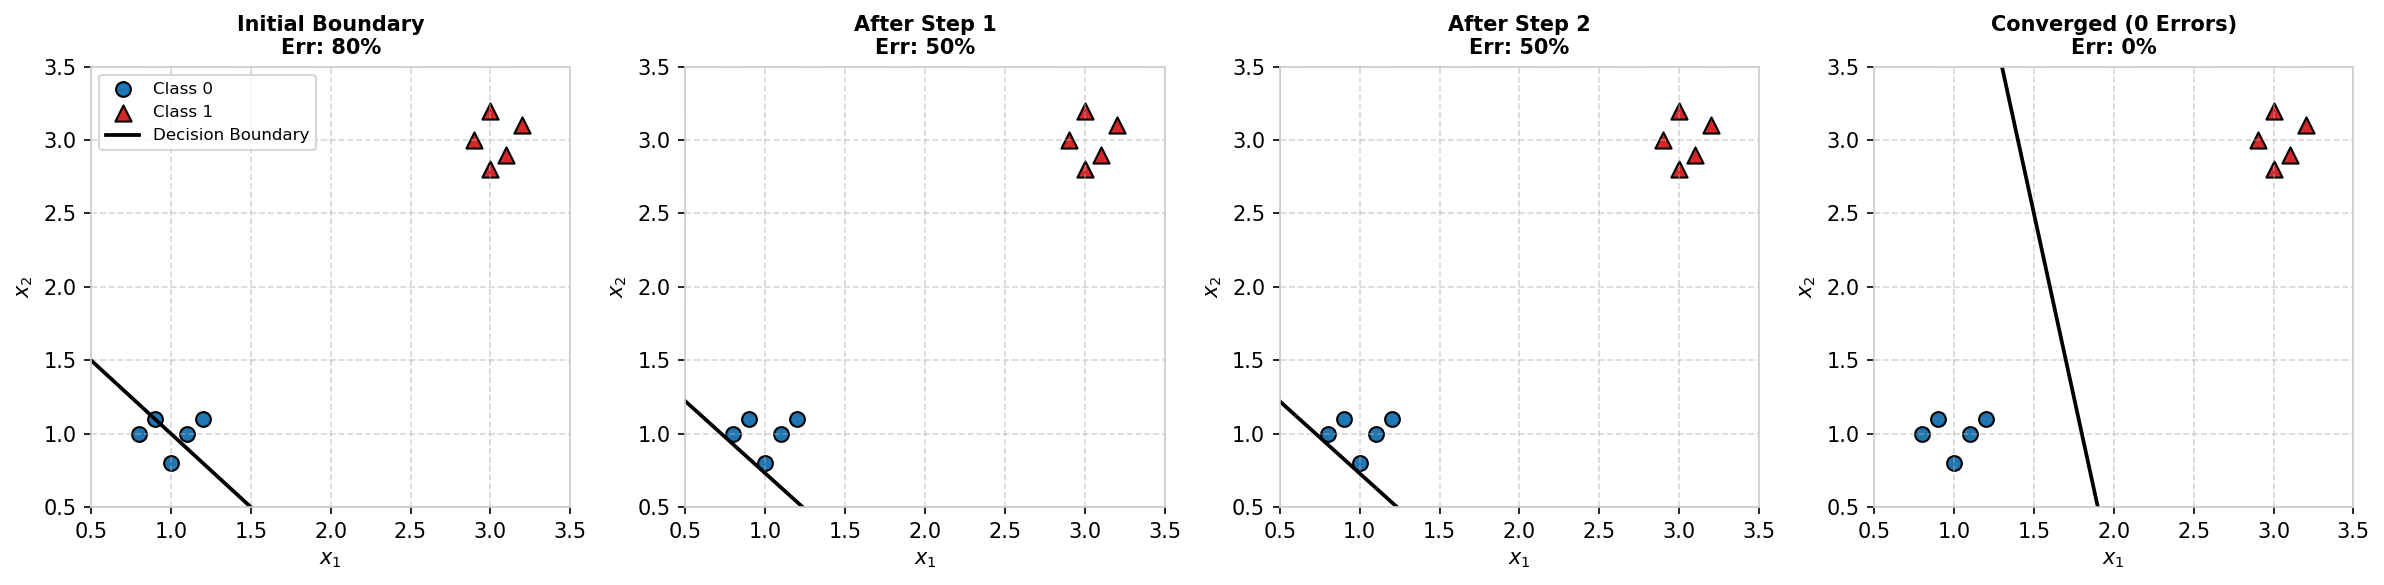

In [33]:
data_q7 = [
    (0.9, 1.1, 0), (1.0, 0.8, 0), (1.1, 1.0, 0), (0.8, 1.0, 0), (1.2, 1.1, 0),
    (3.1, 2.9, 1), (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1)
]

w1, w2, b = -1.0, -1.0, 2.0  # Bad initial boundary (50% initial error)
lr = 0.1
weights_hist = [(w1, w2, b)]
err_hist = [perceptron_dataset_error(data_q7, w1, w2, b)]

for step in range(150):
    rec = data_q7[step % len(data_q7)]
    w1, w2, b = train_perceptron(rec, lr, w1, w2, b)
    err = perceptron_dataset_error(data_q7, w1, w2, b)
    weights_hist.append((w1, w2, b))
    err_hist.append(err)
    if err == 0.0:
        print(f"Convergence achieved at step {step + 1} with 0 errors!")
        print(f"Optimal parameters: w1={w1:.3f}, w2={w2:.3f}, b={b:.3f}")
        break

# Plot consecutive steps
data_arr = np.array(data_q7)
fig, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=150)
sample_steps = [0, 1, 2, len(weights_hist) - 1]
step_labels = ["Initial Boundary", "After Step 1", "After Step 2", "Converged (0 Errors)"]

x_line = np.linspace(0.5, 3.5, 100)
for ax, s_idx, lbl in zip(axes, sample_steps, step_labels):
    cw1, cw2, cb = weights_hist[s_idx]
    ax.scatter(data_arr[data_arr[:, 2] == 0, 0], data_arr[data_arr[:, 2] == 0, 1],
               c='#1f77b4', marker='o', s=50, edgecolors='k', label='Class 0')
    ax.scatter(data_arr[data_arr[:, 2] == 1, 0], data_arr[data_arr[:, 2] == 1, 1],
               c='#d62728', marker='^', s=60, edgecolors='k', label='Class 1')
    if abs(cw2) > 1e-5:
        y_line = -(cw1 * x_line + cb) / cw2
        ax.plot(x_line, y_line, 'k-', linewidth=1.8, label='Decision Boundary')
    ax.set_xlim(0.5, 3.5)
    ax.set_ylim(0.5, 3.5)
    ax.set_title(f"{lbl}\nErr: {err_hist[s_idx]*100:.0f}%", fontsize=10, fontweight='bold')
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.grid(True, linestyle="--", alpha=0.5)
    if s_idx == 0:
        ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()


### Question 8: Non-Linearly Separable Case (Adding $(1.0, 1.0, 1)$)

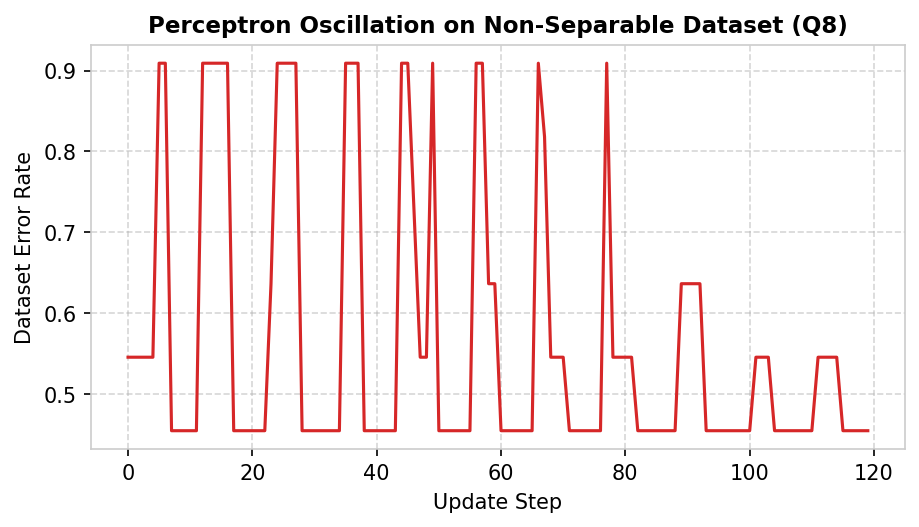

In [34]:
data_q8 = list(data_q7) + [(1.0, 1.0, 1)]
w1, w2, b = -1.0, -1.0, 2.0
q8_err_hist = []

for step in range(300):
    rec = data_q8[step % len(data_q8)]
    w1, w2, b = train_perceptron(rec, 0.1, w1, w2, b)
    err = perceptron_dataset_error(data_q8, w1, w2, b)
    q8_err_hist.append(err)

fig, ax = plt.subplots(figsize=(7, 3.5), dpi=150)
ax.plot(q8_err_hist[:120], color='#d62728', linewidth=1.5)
ax.set_title("Perceptron Oscillation on Non-Separable Dataset (Q8)", fontsize=11, fontweight='bold')
ax.set_xlabel("Update Step")
ax.set_ylabel("Dataset Error Rate")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()


### Question 9: Generalized Single-Unit Artificial Neuron for Regression

#### Mathematical Formulation
For a single record $(x, y)$:
- Pre-activation: $z = w \cdot x + b$
- Output activation: $a = \sigma(z)$
- Chain Rule Gradients:
  $$\frac{\partial C}{\partial a} = \text{cost\_derivative}(y, a)$$
  $$\frac{\partial a}{\partial z} = \text{activation\_derivative}(z, a)$$
  $$\delta = \frac{\partial C}{\partial z} = \frac{\partial C}{\partial a} \cdot \frac{\partial a}{\partial z}$$
  $$\nabla_w C = \delta \cdot x, \quad \nabla_b C = \delta$$
  $$w \leftarrow w - \eta \nabla_w C, \quad b \leftarrow b - \eta \nabla_b C$$


In [35]:
# Activation functions & derivatives
def sigmoid(z): return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
def sigmoid_derivative(z, a=None):
    if a is None: a = sigmoid(z)
    return a * (1.0 - a)

def tanh_func(z): return np.tanh(z)
def tanh_derivative(z, a=None):
    if a is None: a = tanh_func(z)
    return 1.0 - a ** 2

def relu_func(z): return np.maximum(0.0, z)
def relu_derivative(z, a=None): return 1.0 if z > 0.0 else 0.0

def linear_func(z): return z
def linear_derivative(z, a=None): return 1.0

# Cost function derivatives
def cost_derivative_squared_error(y, a): return a - y

def cost_derivative_cross_entropy(y, a):
    eps = 1e-12
    a_clamped = np.clip(a, eps, 1.0 - eps)
    return (a_clamped - y) / (a_clamped * (1.0 - a_clamped))

def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative,
                 activation_func=linear_func):
    x, y = training_record
    z = w * x + b
    a = activation_func(z)
    
    dC_da = cost_derivative(y, a)
    da_dz = activation_derivative(z, a)
    delta = dC_da * da_dz
    
    grad_w = delta * x
    grad_b = delta
    
    w_new = w - learning_rate * grad_w
    b_new = b - learning_rate * grad_b
    return w_new, b_new, grad_w, grad_b


#### Question 9a: Regression Learning Animation on $y = 2x + 3 + \epsilon$

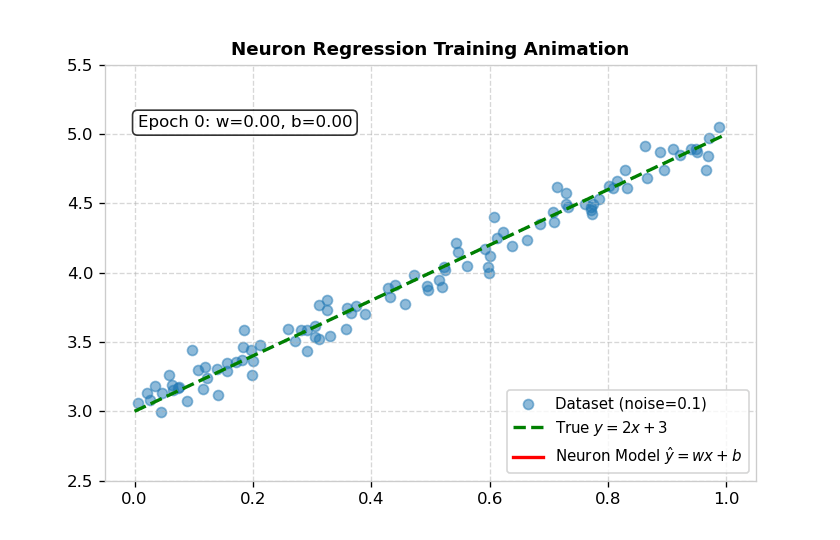

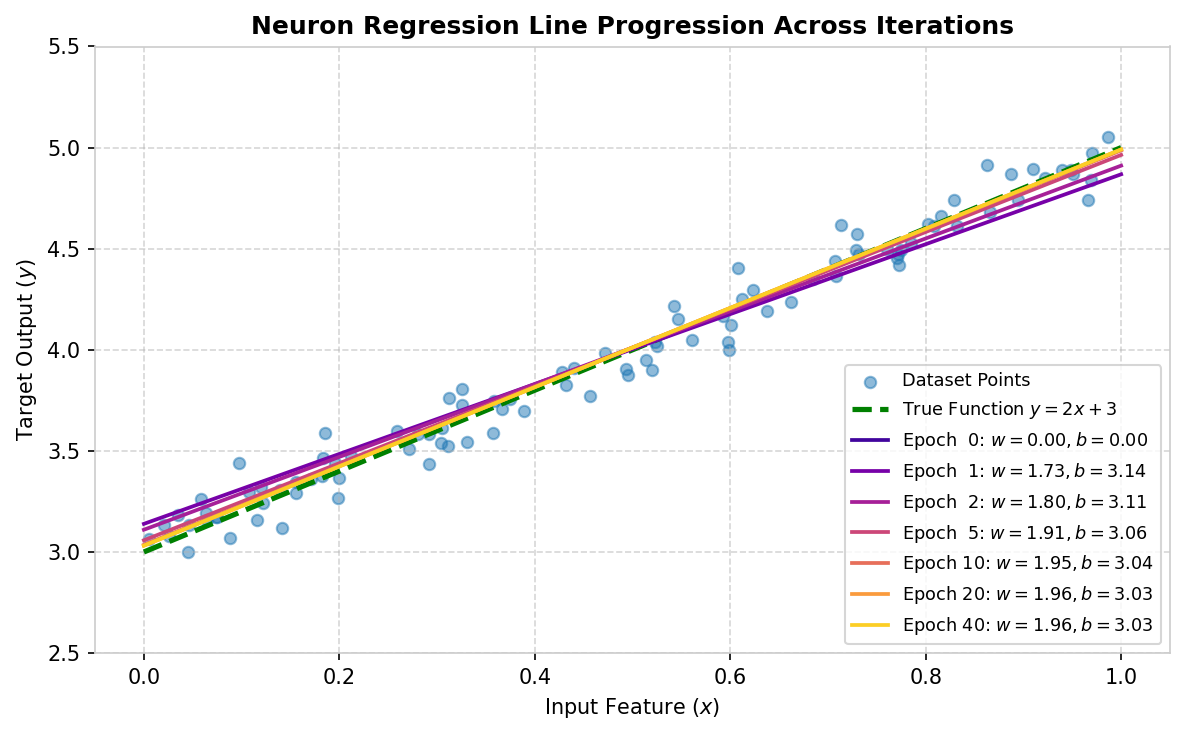

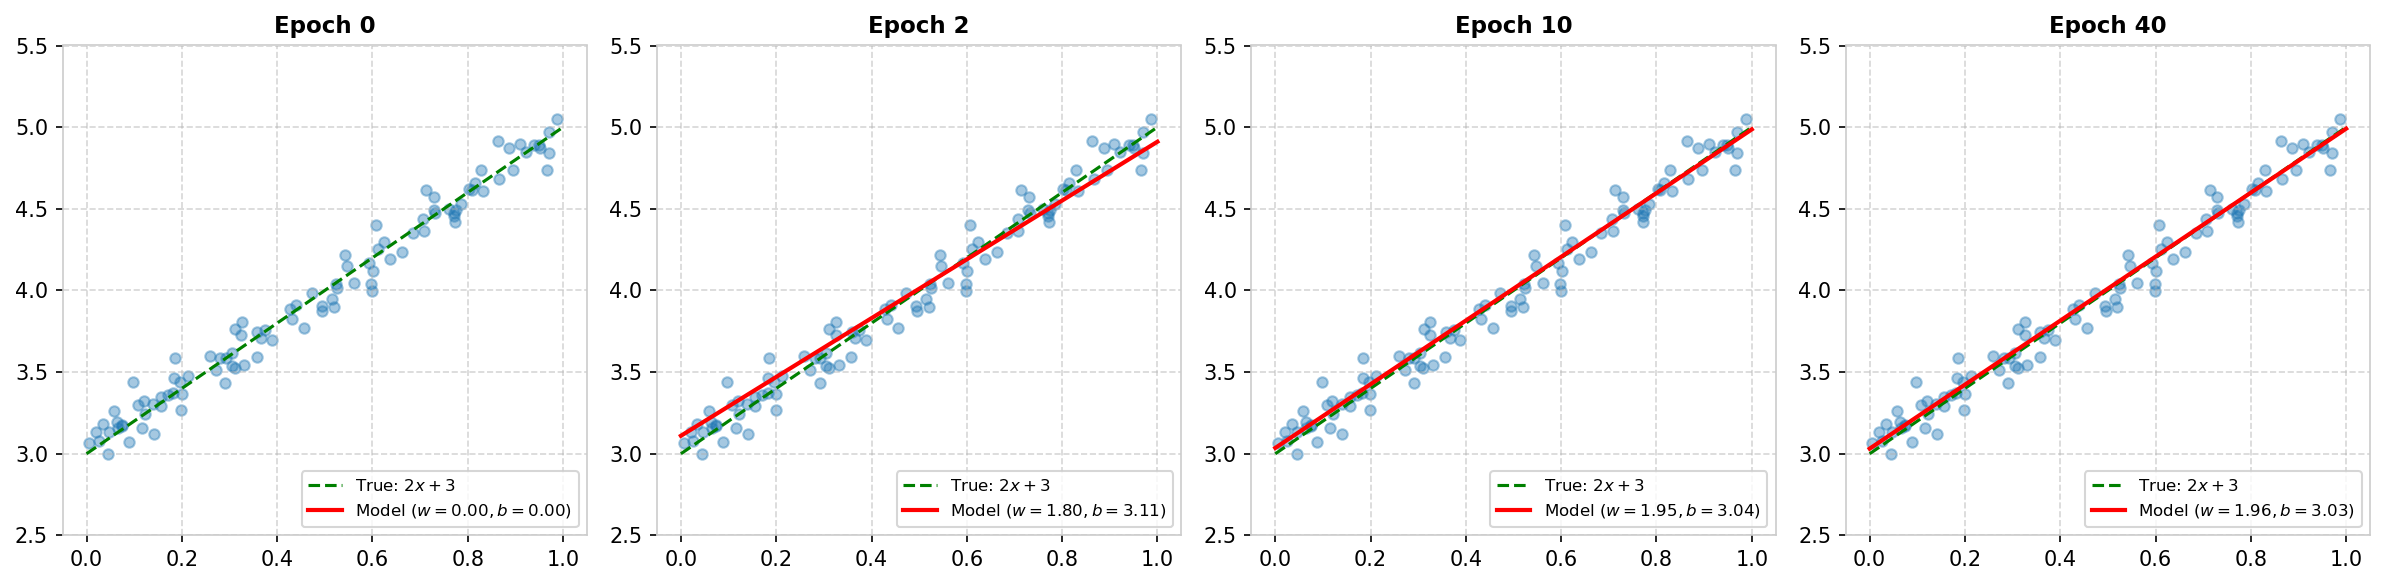

In [36]:
# 9a. Movie-like Animation and Visual Progression of Neuron Learning y = 2x + 3
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display, Image

os.makedirs('figures', exist_ok=True)
np.random.seed(42)
x_data = np.random.uniform(0.0, 1.0, 100)
noise = np.random.normal(0.0, 0.1, 100)
y_data = 2.0 * x_data + 3.0 + noise
records = list(zip(x_data, y_data))

# Train linear neuron
w, b = 0.0, 0.0
lr = 0.05
epochs = 40
history_wb = [(w, b)]
grad_w_epochs, grad_b_epochs = [], []

for ep in range(epochs):
    ep_gw, ep_gb = 0.0, 0.0
    for rec in records:
        w, b, gw, gb = train_neuron(rec, lr, w, b, cost_derivative_squared_error, linear_derivative, linear_func)
        ep_gw += abs(gw)
        ep_gb += abs(gb)
    history_wb.append((w, b))
    grad_w_epochs.append(ep_gw / len(records))
    grad_b_epochs.append(ep_gb / len(records))

# -------------------------------------------------------------
# 1. Movie-like Animation (Rendered as Animated GIF & Interactive Widget)
# -------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
ax.scatter(x_data, y_data, c='#1f77b4', alpha=0.5, label='Dataset (noise=0.1)')
x_grid = np.linspace(0, 1, 100)
ax.plot(x_grid, 2*x_grid + 3, 'g--', linewidth=2, label=r'True $y = 2x + 3$')
line_pred, = ax.plot(x_grid, history_wb[0][0]*x_grid + history_wb[0][1], 'r-', linewidth=2, label=r'Neuron Model $\hat{y} = wx + b$')
txt = ax.text(0.05, 0.85, f"Epoch 0: w={history_wb[0][0]:.2f}, b={history_wb[0][1]:.2f}",
              transform=ax.transAxes, fontsize=10, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(2.5, 5.5)
ax.set_title("Neuron Regression Training Animation", fontsize=11, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, linestyle="--", alpha=0.5)

def animate(frame):
    cw, cb = history_wb[frame]
    line_pred.set_data(x_grid, cw*x_grid + cb)
    txt.set_text(f"Epoch {frame}: w={cw:.2f}, b={cb:.2f}")
    return line_pred, txt

ani = animation.FuncAnimation(fig, animate, frames=len(history_wb), interval=100, blit=False)

gif_path = 'figures/q9_regression_animation.gif'
ani.save(gif_path, writer=animation.PillowWriter(fps=5))
plt.close(fig)

# Display animated GIF in notebook
display(Image(filename=gif_path))

try:
    display(HTML(ani.to_jshtml()))
except Exception:
    pass

# -------------------------------------------------------------
# 2. Plotted Progression Images
# -------------------------------------------------------------
fig_prog, ax_prog = plt.subplots(figsize=(8, 5), dpi=150)
ax_prog.scatter(x_data, y_data, c='#1f77b4', alpha=0.5, s=30, label='Dataset Points')
ax_prog.plot(x_grid, 2*x_grid + 3, 'g--', linewidth=2.5, label=r'True Function $y = 2x + 3$')

sample_epochs = [0, 1, 2, 5, 10, 20, len(history_wb) - 1]
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(sample_epochs)))

for ep, col in zip(sample_epochs, colors):
    cw, cb = history_wb[ep]
    ax_prog.plot(x_grid, cw*x_grid + cb, color=col, linewidth=1.8,
                 label=f"Epoch {ep:2d}: $w={cw:.2f}, b={cb:.2f}$")

ax_prog.set_title("Neuron Regression Line Progression Across Iterations", fontsize=12, fontweight='bold')
ax_prog.set_xlabel("Input Feature ($x$)")
ax_prog.set_ylabel("Target Output ($y$)")
ax_prog.set_xlim(-0.05, 1.05)
ax_prog.set_ylim(2.5, 5.5)
ax_prog.grid(True, linestyle="--", alpha=0.5)
ax_prog.legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 3. Side-by-Side Snapshots of Key Epochs
# -------------------------------------------------------------
fig_snap, axes = plt.subplots(1, 4, figsize=(16, 4), dpi=150)
snapshot_epochs = [0, 2, 10, len(history_wb) - 1]

for ax_s, ep in zip(axes, snapshot_epochs):
    cw, cb = history_wb[ep]
    ax_s.scatter(x_data, y_data, c='#1f77b4', alpha=0.4, s=25)
    ax_s.plot(x_grid, 2*x_grid + 3, 'g--', linewidth=1.5, label='True: $2x+3$')
    ax_s.plot(x_grid, cw*x_grid + cb, 'r-', linewidth=2, label=f'Model ($w={cw:.2f}, b={cb:.2f}$)')
    ax_s.set_title(f"Epoch {ep}", fontsize=11, fontweight='bold')
    ax_s.set_xlim(-0.05, 1.05)
    ax_s.set_ylim(2.5, 5.5)
    ax_s.grid(True, linestyle="--", alpha=0.5)
    ax_s.legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()


#### Question 9c & 9d: Learning Rates & Gradient Magnitudes Across Epochs

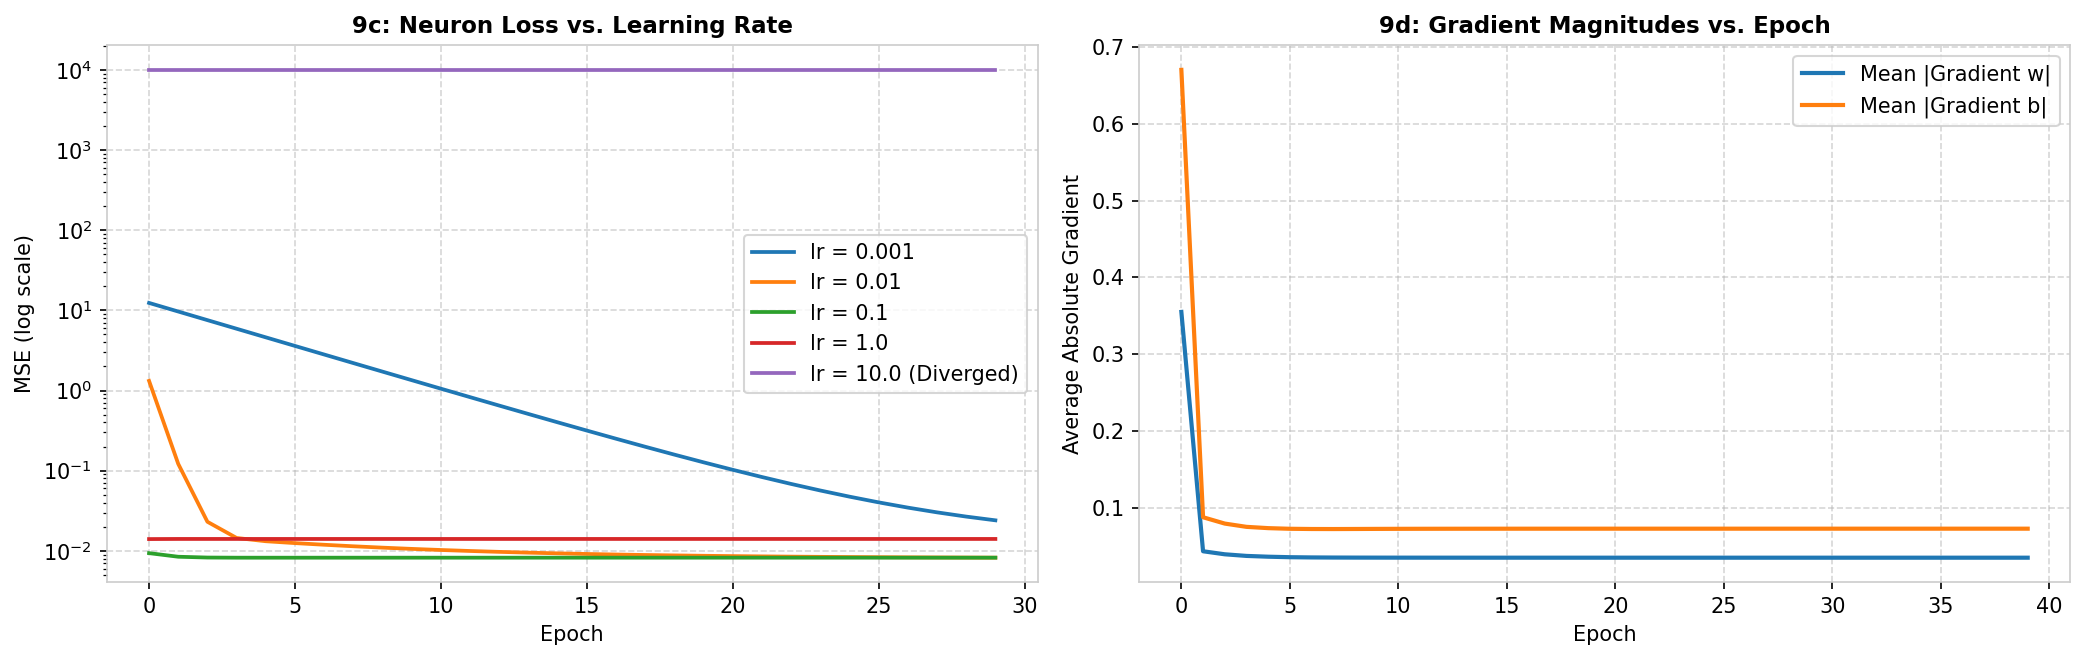

In [37]:
# 9c: Learning Rate Sweeps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), dpi=150)
lrs = [0.001, 0.01, 0.1, 1.0, 10.0]

for test_lr in lrs:
    cw, cb = 0.0, 0.0
    mses = []
    diverged = False
    for ep in range(30):
        for rec in records:
            cw, cb, _, _ = train_neuron(rec, test_lr, cw, cb, cost_derivative_squared_error, linear_derivative, linear_func)
            if (not np.isfinite(cw) or not np.isfinite(cb)
                or abs(cw) > 1e4 or abs(cb) > 1e4):
                diverged = True
                break
        if diverged:
            mses.extend([1e4] * (30 - len(mses)))
            break
        mses.append(np.mean((cw * x_data + cb - y_data) ** 2))
    ax1.plot(mses, label=f"lr = {test_lr} {'(Diverged)' if diverged else ''}", linewidth=1.8)

ax1.set_yscale('log')
ax1.set_title("9c: Neuron Loss vs. Learning Rate", fontsize=11, fontweight='bold')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MSE (log scale)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

# 9d: Gradient Evolution
ax2.plot(grad_w_epochs, label='Mean |Gradient w|', color='#1f77b4', linewidth=2)
ax2.plot(grad_b_epochs, label='Mean |Gradient b|', color='#ff7f0e', linewidth=2)
ax2.set_title("9d: Gradient Magnitudes vs. Epoch", fontsize=11, fontweight='bold')
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Average Absolute Gradient")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


---
# Part 3: Multi-Layer Perceptron & Gradient Flow Analysis (Questions 10–12)

### Architecture & Experimental Configuration from Demo Notebook
- **Network Depth:** 4 hidden layers of 32 units each + 1 output layer of 10 units = **5 layers total**
- **Activations:** All 5 layers use **Sigmoid** activation
- **Cost Function:** **Mean Squared Error (MSE)**


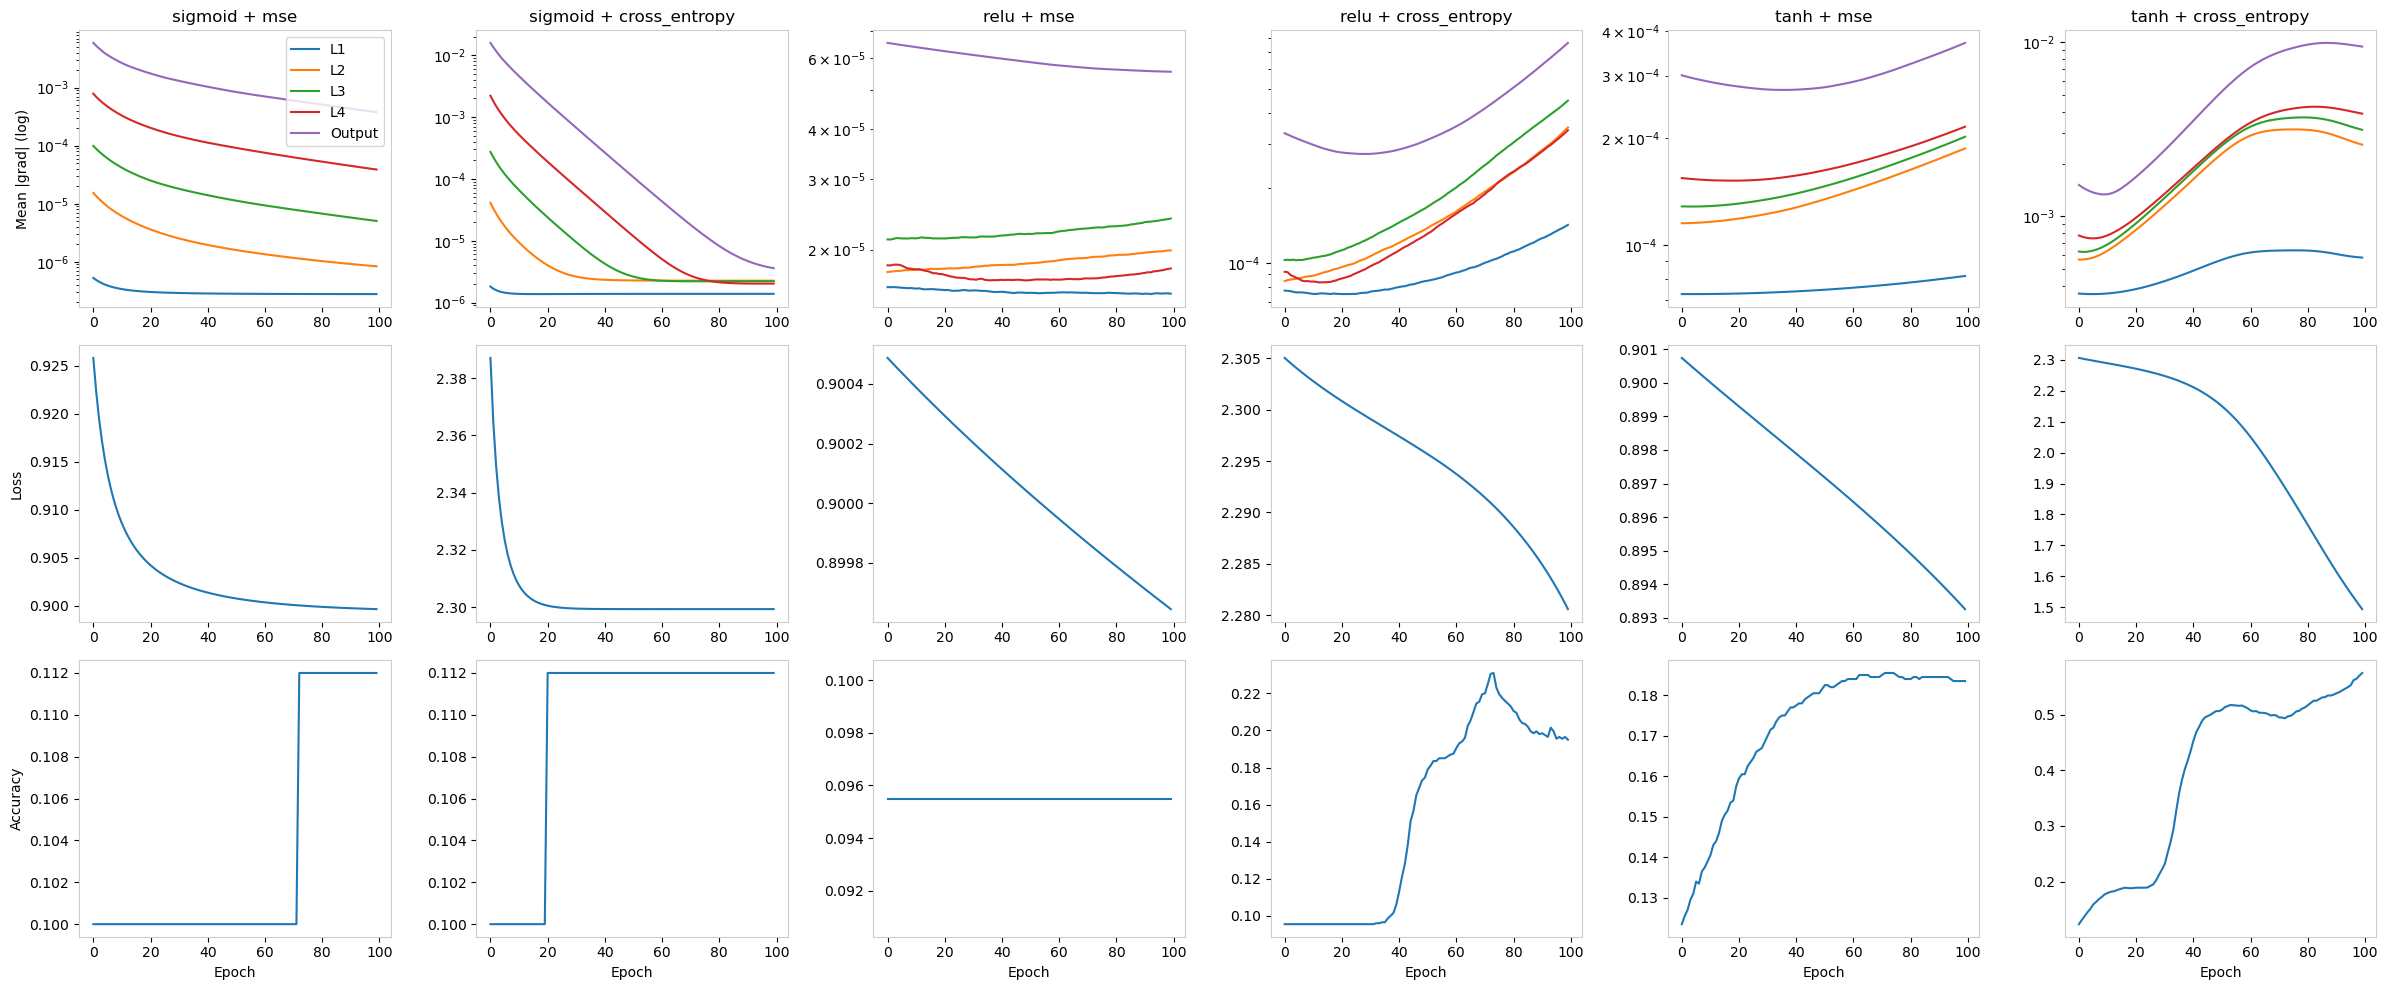

In [38]:
import torch, torch.nn as nn, torch.nn.functional as F, numpy as np
from torchvision import datasets, transforms

ds = datasets.MNIST('.', train=True, download=True, transform=transforms.ToTensor())
X = ds.data[:2000].float().div(255).view(-1, 784)
y = ds.targets[:2000]

def run(act, cost, epochs=100, lr=0.1, hidden=(32,32,32,32)):
    torch.manual_seed(42)
    f = {'sigmoid': torch.sigmoid, 'relu': F.relu, 'tanh': torch.tanh}[act]
    sizes = [784, *hidden, 10]
    layers = nn.ModuleList(nn.Linear(a, b) for a, b in zip(sizes, sizes[1:]))
    def fwd(x):
        for l in layers[:-1]: x = f(l(x))
        return layers[-1](x)          # logits, no output activation
    hist = {'grad': [], 'loss': [], 'acc': []}
    for _ in range(epochs):
        layers.zero_grad()
        out = fwd(X)
        loss = (F.mse_loss(out.softmax(1), F.one_hot(y,10).float(), reduction='sum')/len(X)
                if cost == 'mse' else F.cross_entropy(out, y))
        loss.backward()
        hist['grad'].append([l.weight.grad.abs().mean().item() for l in layers])
        hist['loss'].append(loss.item())
        hist['acc'].append((out.argmax(1) == y).float().mean().item())
        with torch.no_grad():
            for p in layers.parameters(): p -= lr * p.grad
    return {k: np.array(v) for k, v in hist.items()}

results = {(a, c): run(a, c) for a in ['sigmoid','relu','tanh'] for c in ['mse','cross_entropy']}
fig, axes = plt.subplots(3, 6, figsize=(24, 10))
for j, ((act, cost), h) in enumerate(results.items()):
    for i in range(5):
        axes[0, j].plot(h['grad'][:, i], label=f'L{i+1}' if i < 4 else 'Output')
    axes[0, j].set_yscale('log')
    axes[0, j].set_title(f'{act} + {cost}')
    axes[1, j].plot(h['loss'])
    axes[2, j].plot(h['acc'])
    axes[2, j].set_xlabel('Epoch')

axes[0, 0].set_ylabel('Mean |grad| (log)')
axes[1, 0].set_ylabel('Loss')
axes[2, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
plt.tight_layout()
plt.show()